In [1]:
# Project paths: run Jupyter from this repository or a notebook subdirectory.
# Saved outputs are from the original archive; they have not been recomputed.
from pathlib import Path
import os

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data" / "random_numbers.npz").is_file()), None
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter inside the monsoon_bias_MAP24 repository.")
DATA_DIR = Path(os.environ.get("PRECIP_DATA_DIR", str(PROJECT_ROOT / "data"))).expanduser()
WEIGHTS_DIR = Path(os.environ.get("PRECIP_WEIGHTS_DIR", str(PROJECT_ROOT / "models"))).expanduser()
RESULTS_DIR = PROJECT_ROOT / "results"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

import h5py
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, GlobalAveragePooling1D, LSTM, Dense
from tensorflow.keras.layers import Dropout, Input, Add,  Conv2DTranspose, Reshape
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
import matplotlib.pyplot as plt
import os
import random
import xarray as xr
import pickle
from sklearn.preprocessing import StandardScaler
import dask
import dask.dataframe as dd
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras import layers, models
from dask.distributed import Client
client = Client()

In [2]:
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

In [3]:
data=np.load(str(DATA_DIR / "ml_data_pr.npz"))
X0=data['X']
Y=data['Y']

# GEOS-S2S-3 VP data for forecast month
data1=np.load(str(DATA_DIR / "ml_data1.npz"))
X1=data1['X1']
X1[np.isnan(X1)]=np.nanmean(X1)

# M2 VP data for forecast month 
data2=np.load(str(DATA_DIR / "ml_data2.npz"))
X2=data2['X1']
X2[np.isnan(X2)]=np.nanmean(X2)

nx=len(data['lon'])
ny=len(data['lat'])

lon1=(data1['lon1'])
lat1=(data1['lat1'])

lon=(data['lon'])
lat=(data['lat'])
date=(data['date'])

In [4]:
# fig=plt.figure(figsize=(11.5,8))
# clf=np.arange(-4,4.1,1)*1e6
# plot((X1-X2)[0,:,:,0],lon1,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig,)


In [5]:
# X1=X1-X2

In [6]:
x0mean = X0.mean()
x0std = X0.std()

# Normalize the data
normalized_X0 = (X0 - x0mean) / x0std

In [7]:
x1mean = X1.mean()
x1std = X1.std()

# Normalize the data
normalized_X1 = (X1 - x1mean) / x1std

In [8]:
x2mean = X2.mean()
x2std = X2.std()

# Normalize the data
normalized_X2 = (X2 - x2mean) / x2std

In [9]:
normalized_X=np.concatenate((normalized_X0,normalized_X1, normalized_X2 ),axis=3)

# normalized_X=np.concatenate((X0,X1),axis=3)
# normalized_Y=Y

In [10]:
ymean = Y.mean()
ystd = Y.std()

# Normalize the data
normalized_Y = (Y - ymean) / ystd


In [11]:
# import random
# random_numbers = random.sample(range(0, (len(X))),len(X))

In [12]:
#np.savez(str(PROJECT_ROOT / "data" / "random_numbers.npz"),random_numbers=random_numbers)
random_numbers=np.load(str(PROJECT_ROOT / "data" / "random_numbers.npz"))['random_numbers']

In [13]:
normalized_X=normalized_X[random_numbers,:,:,:]
normalized_Y=normalized_Y[random_numbers,:,:,:]
date=date[random_numbers]

In [14]:
# normalized_Y=Y
# normalized_X=X

In [67]:
nf = 7  # number of input features
nv = 2  # number of variables to be forecasted
nx = 101  # spatial dimension width
ny = 91   # spatial dimension height

# Define the input shape
input_shape = (ny, nx, nf)

model = models.Sequential()

# First convolutional layer with 32 filters, 3x3 kernel size
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape))
model.add(layers.BatchNormalization())  # Helps in normalizing the activations and gradients

# Second convolutional layer with 64 filters, 3x3 kernel size
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Additional convolutional layer with 128 filters
model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Additional convolutional layer with 128 filters
model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

model.add(layers.Conv2D(512, (3, 3), activation='relu', padding='same'))
model.add(layers.BatchNormalization())

# Final layer to produce the output with `nv` channels
model.add(layers.Conv2D(nv, (1, 1), activation='linear', padding='same'))

# Compile the model
model.compile(optimizer='adam', loss='mse')

# Display the model summary
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_82 (Conv2D)           (None, 91, 101, 32)       2048      
_________________________________________________________________
batch_normalization_78 (Batc (None, 91, 101, 32)       128       
_________________________________________________________________
conv2d_83 (Conv2D)           (None, 91, 101, 64)       18496     
_________________________________________________________________
batch_normalization_79 (Batc (None, 91, 101, 64)       256       
_________________________________________________________________
conv2d_84 (Conv2D)           (None, 91, 101, 128)      73856     
_________________________________________________________________
batch_normalization_80 (Batc (None, 91, 101, 128)      512       
_________________________________________________________________
conv2d_85 (Conv2D)           (None, 91, 101, 256)     

In [68]:
# import tensorflow as tf
# from tensorflow.keras import layers, models

# def conv_block(input_tensor, num_filters):
#     """A block of two convolutional layers with ReLU and batch normalization."""
#     x = layers.Conv2D(num_filters, 3, padding="same")(input_tensor)
#     x = layers.BatchNormalization()(x)
#     x = layers.Activation("relu")(x)

#     x = layers.Conv2D(num_filters, 3, padding="same")(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.Activation("relu")(x)
    
#     return x

# def encoder_block(input_tensor, num_filters):
#     """A block for the downsampling path."""
#     x = conv_block(input_tensor, num_filters)
#     p = layers.MaxPooling2D((2, 2))(x)
#     return x, p

# def decoder_block(input_tensor, concat_tensor, num_filters, strides=(2, 2), kernel_size=(2, 2)):
#     """A block for the upsampling path that can adjust strides and kernel sizes dynamically."""
#     x = layers.Conv2DTranspose(num_filters, kernel_size, strides=strides, padding="same")(input_tensor)
#     # Calculate the padding needed to match the shapes
#     padding_height = concat_tensor.shape[1] - x.shape[1]
#     padding_width = concat_tensor.shape[2] - x.shape[2]
#     x = layers.ZeroPadding2D(((padding_height//2, padding_height - padding_height//2),
#                               (padding_width//2, padding_width - padding_width//2)))(x)
#     x = layers.concatenate([x, concat_tensor])  # Skip connection
#     x = conv_block(x, num_filters)
#     return x


# def unet_model():
#     inputs = layers.Input(shape=(91, 101, 7))
    
#     # Encoding path
#     x1, p1 = encoder_block(inputs, 32)
#     x2, p2 = encoder_block(p1, 64)
#     x3, p3 = encoder_block(p2, 128)
#     x4, p4 = encoder_block(p3, 256)
    
#     # Bottleneck
#     b = conv_block(p4, 512)

#     # Decoding path
#     d1 = decoder_block(b, x4, 256)
#     d2 = decoder_block(d1, x3, 128)
#     d3 = decoder_block(d2, x2, 64)
#     d4 = decoder_block(d3, x1, 32)
    
#     # Output
#     outputs = layers.Conv2D(2, 1, activation='sigmoid', padding='same')(d4)  # 2 output variables
    
#     model = models.Model(inputs, outputs)
#     return model

# # Create the U-Net model
# model = unet_model()
# model.summary()
# model.compile(optimizer='adam', loss='mean_squared_error', metrics=['accuracy'])

In [121]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input

# Assuming 'input_shape' and 'nv' are defined
input_shape = (91, 101, 7)  # Example input shape
nv = 2  # Number of variables to predict

# Input layer
inputs = Input(shape=input_shape)

# First convolutional layer with 32 filters, 3x3 kernel size
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
x = layers.BatchNormalization()(x)

# Second convolutional layer with 64 filters, 3x3 kernel size
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)

# Additional convolutional layer with 128 filters
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)

# Additional convolutional layer with 256 filters
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)

# Convolutional layer with 512 filters
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)

# Intermediate output for deep supervision
intermediate_output = layers.Conv2D(nv, (1, 1), activation='linear', padding='same')(x)

# Additional processing after intermediate output
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)

# Final output layer
final_output = layers.Conv2D(nv, (1, 1), activation='linear', padding='same')(x)

# Create the model with inputs and two outputs
model = models.Model(inputs=inputs, outputs=[intermediate_output, final_output])

# Compile the model with losses for each output
model.compile(optimizer='adam', loss='mse', loss_weights=[0.5, 1.0])

# Display the model summary
model.summary()


Model: "model_3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_6 (InputLayer)            [(None, 91, 101, 7)] 0                                            
__________________________________________________________________________________________________
conv2d_88 (Conv2D)              (None, 91, 101, 32)  2048        input_6[0][0]                    
__________________________________________________________________________________________________
batch_normalization_83 (BatchNo (None, 91, 101, 32)  128         conv2d_88[0][0]                  
__________________________________________________________________________________________________
conv2d_89 (Conv2D)              (None, 91, 101, 64)  18496       batch_normalization_83[0][0]     
____________________________________________________________________________________________

In [122]:
X_norm_train=normalized_X[0:500,:,:,:]
Y_norm_train=normalized_Y[0:500,:,:,:]

In [123]:
X_norm_test=normalized_X[500:,:,:,:]
Y_norm_test=normalized_Y[500:,:,:,:]

In [124]:
model_weights_path = str(WEIGHTS_DIR / "best_model_weights_unet.h5")

In [125]:
try:
    model.load_weights(model_weights_path)
    print("Loaded weights from previous model!")
except:
    print("No previous weights found, starting from scratch.")

No previous weights found, starting from scratch.


In [166]:

    

checkpoint = ModelCheckpoint(model_weights_path, save_best_only=True, save_weights_only=True, monitor='val_loss', mode='min',verbose=1)

history = model.fit(X_norm_train, Y_norm_train, epochs=300, batch_size=32, validation_split=.1, callbacks=[checkpoint])

Epoch 1/300
14/15 [===========================>..] - ETA: 0s - loss: 0.4748 - conv2d_93_loss: 0.3242 - conv2d_95_loss: 0.3127
Epoch 00001: val_loss improved from inf to 0.47634, saving model to /home/afahad/nb/precip_SA/best_model_weights_unet.h5
15/15 [==============================] - 3s 177ms/step - loss: 0.4748 - conv2d_93_loss: 0.3242 - conv2d_95_loss: 0.3126 - val_loss: 0.4763 - val_conv2d_93_loss: 0.3247 - val_conv2d_95_loss: 0.3140
Epoch 2/300
14/15 [===========================>..] - ETA: 0s - loss: 0.4740 - conv2d_93_loss: 0.3258 - conv2d_95_loss: 0.3111
Epoch 00002: val_loss improved from 0.47634 to 0.46827, saving model to /home/afahad/nb/precip_SA/best_model_weights_unet.h5
15/15 [==============================] - 3s 176ms/step - loss: 0.4754 - conv2d_93_loss: 0.3267 - conv2d_95_loss: 0.3120 - val_loss: 0.4683 - val_conv2d_93_loss: 0.3170 - val_conv2d_95_loss: 0.3098
Epoch 3/300
14/15 [===========================>..] - ETA: 0s - loss: 0.4693 - conv2d_93_loss: 0.3206 - conv2

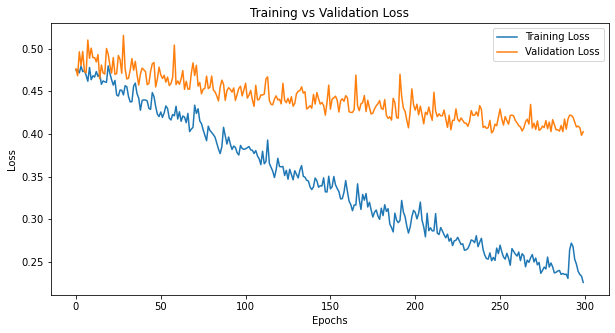

In [167]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plotting the training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

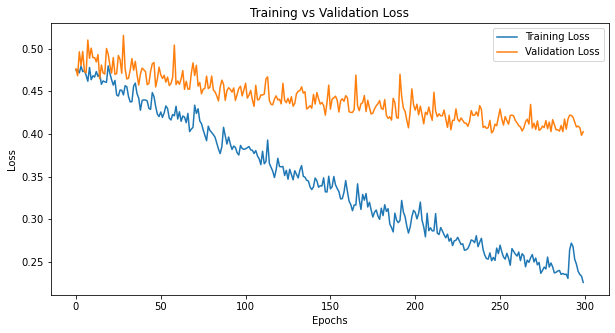

In [168]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Plotting the training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [169]:
# load best model

model.load_weights(str(WEIGHTS_DIR / "best_model_weights_unet.h5"))

In [170]:
#testing

#Test

Yp_norm_test = model.predict(X_norm_test)

In [171]:
Yp_norm_test=Yp_norm_test[1]

In [172]:
# 1. Load the saved scaler for Y from the pickle file
# 4. Reshape back to original 5D shape
original_Yp = Yp_norm_test * ystd + ymean
original_Y = Y_norm_test * ystd + ymean

original_X = X_norm_test * x0std + x0mean

In [173]:
# 1. Load the saved scaler for Y from the pickle file
# 4. Reshape back to original 5D shape
# original_Yp = Yp_norm_test# * ystd + ymean
# original_Y = Y_norm_test #* ystd + ymean

# original_X = X_norm_test# * xstd + xmean

In [174]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.045):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree())

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    try:
        ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    except:
        None

    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


Text(0.5, 0.98, '1 months lead mean')

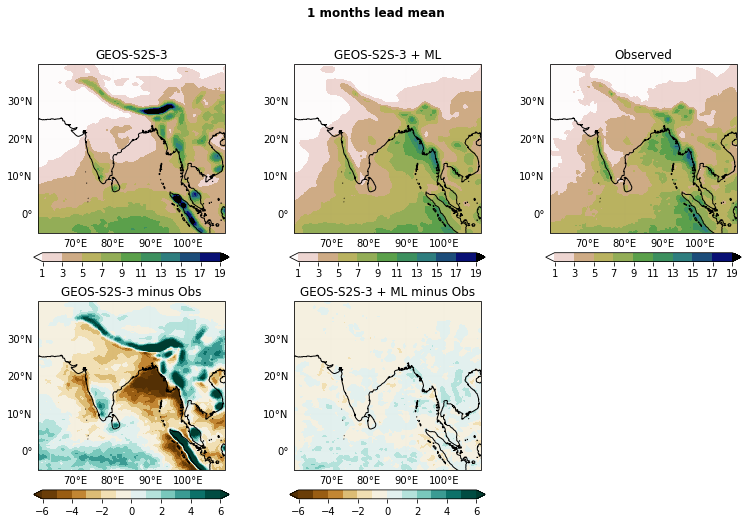

In [175]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=34
l=0
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')



plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')


Text(0.5, 0.98, '2 months lead mean')

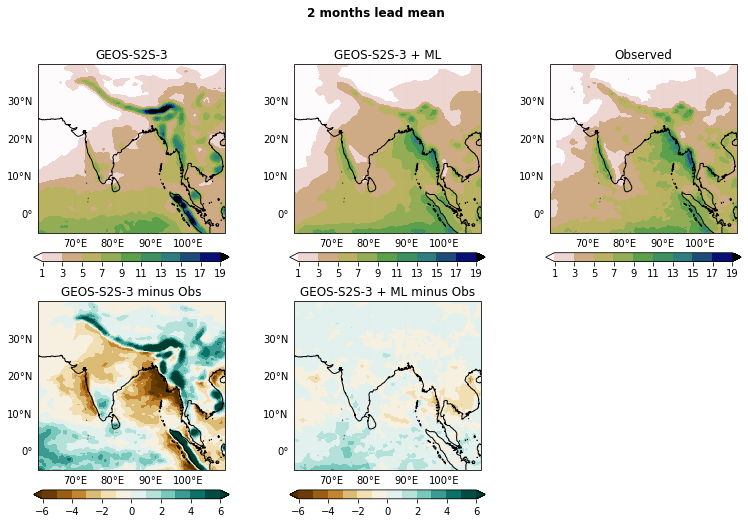

In [176]:
clf=np.arange(1,21,2)
cmap='gist_earth_r'

nn=34
l=1
fig=plt.figure(figsize=(13,8))

plot(np.nanmean(original_Yp[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
plt.title('GEOS-S2S-3 + ML')

plot(np.nanmean(original_X[:,:,:,l+1],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
plt.title('GEOS-S2S-3')

plot(np.nanmean(original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
plt.title('Observed')

clf=np.arange(-6,6.1,1)
cmap='BrBG'


plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
plt.title('GEOS-S2S-3 + ML minus Obs')

plot(np.nanmean(original_X[:,:,:,l+1]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
plt.title('GEOS-S2S-3 minus Obs')
plt.suptitle(str(l+1)+' months lead mean',fontsize=12,fontweight='bold')

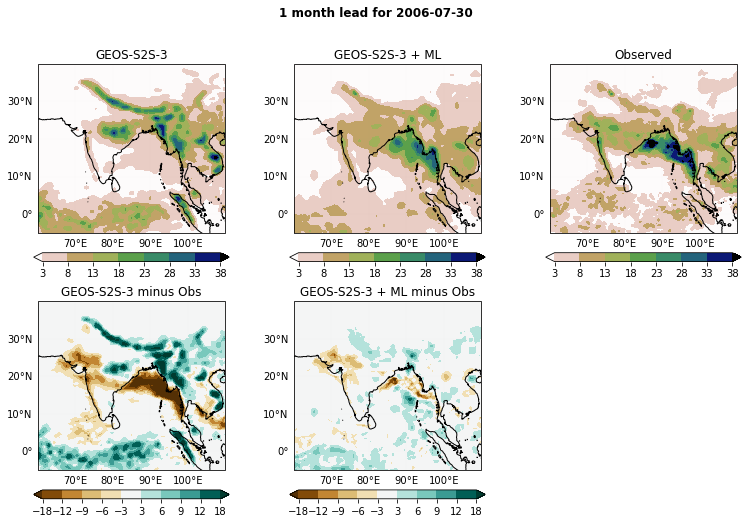

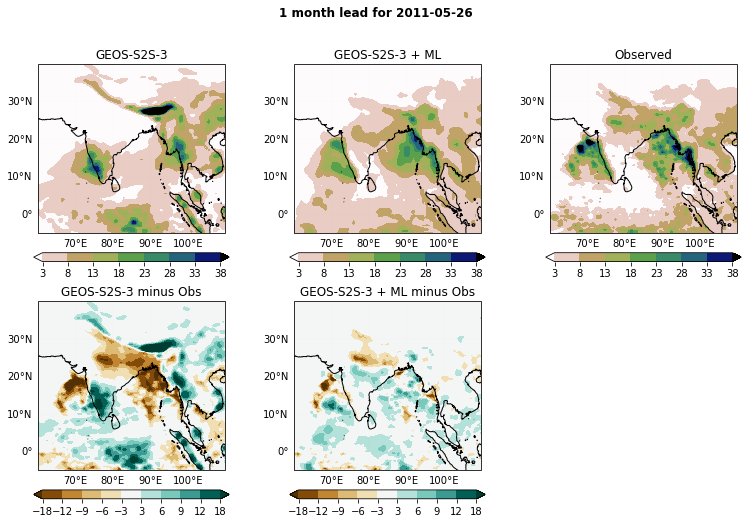

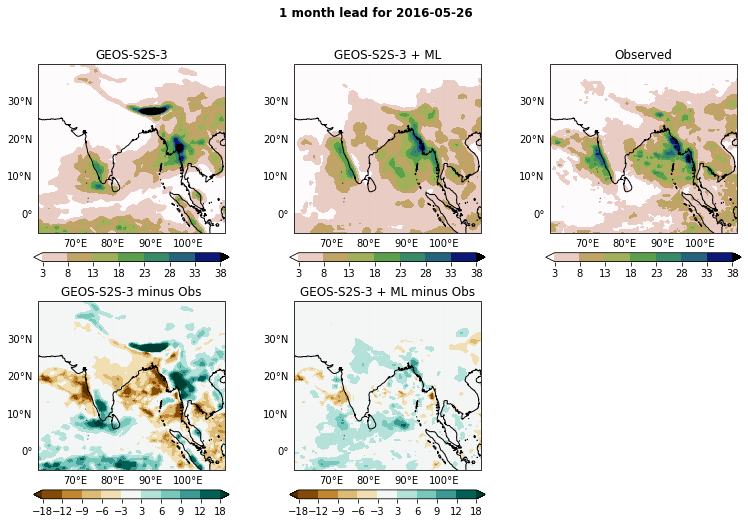

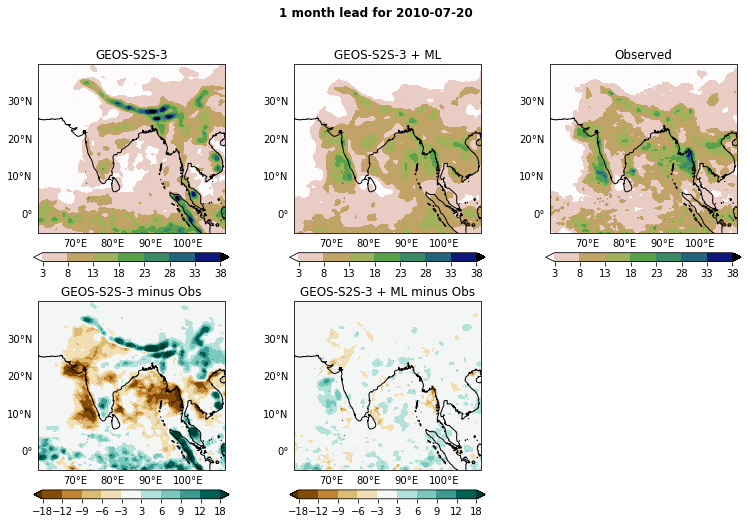

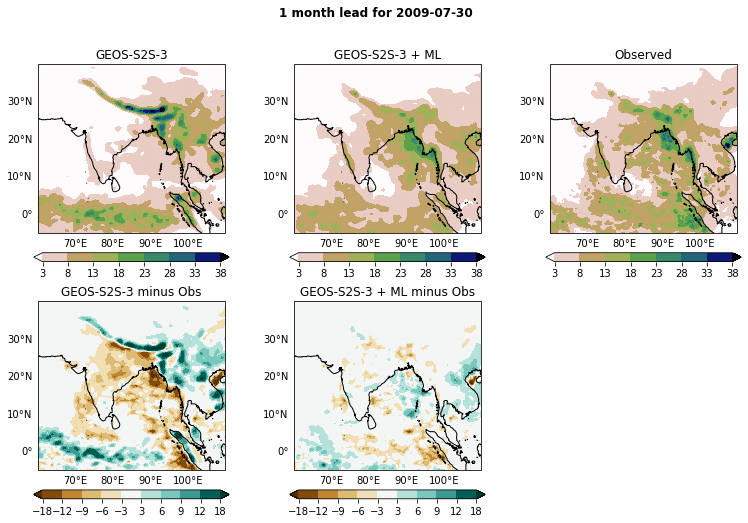

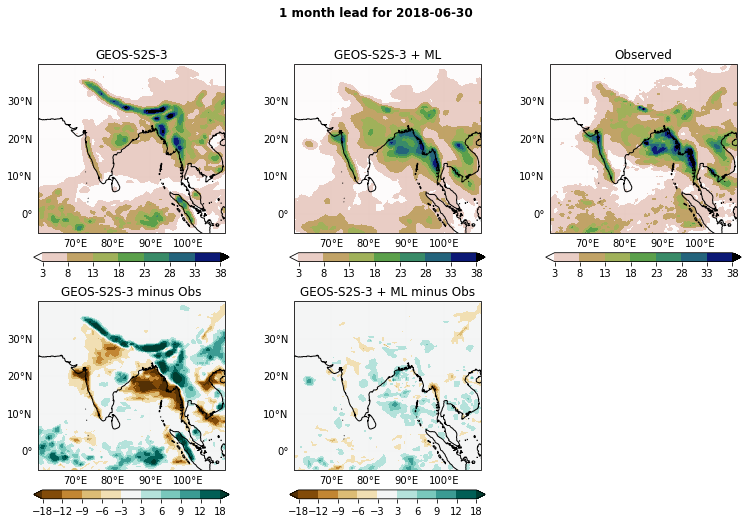

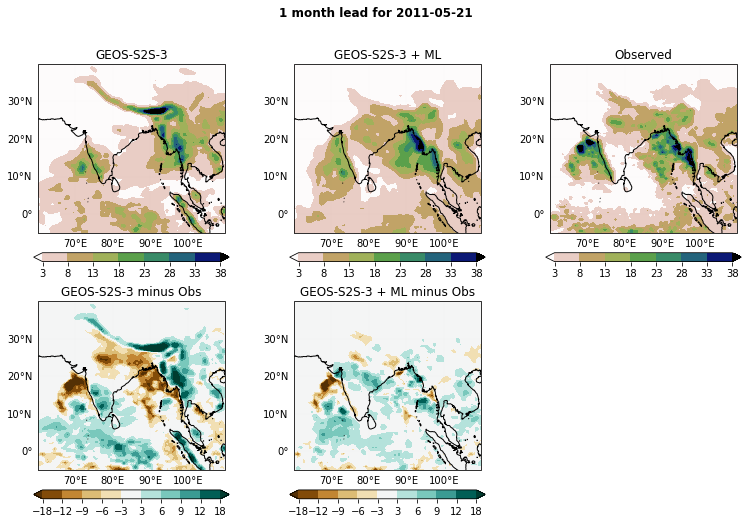

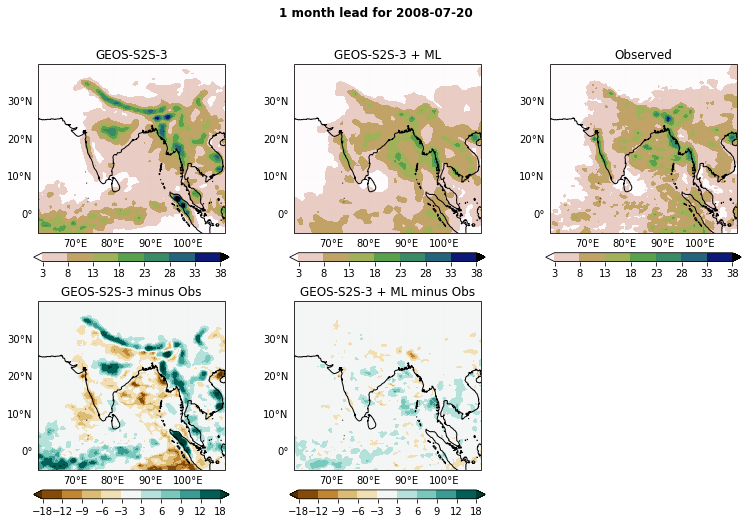

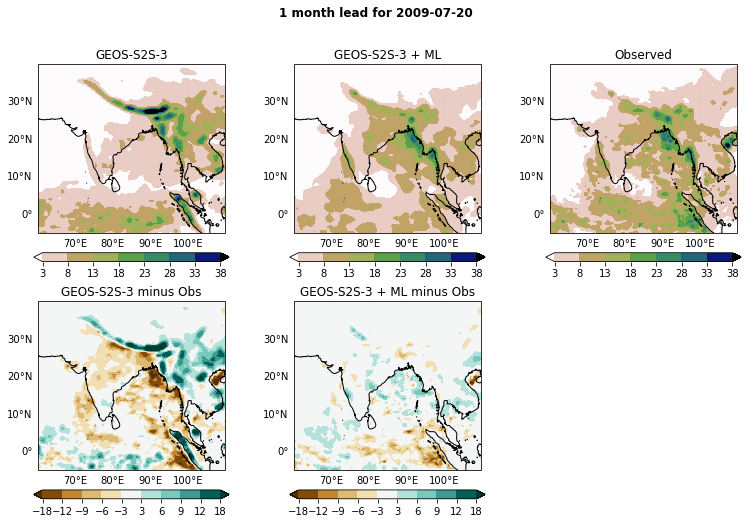

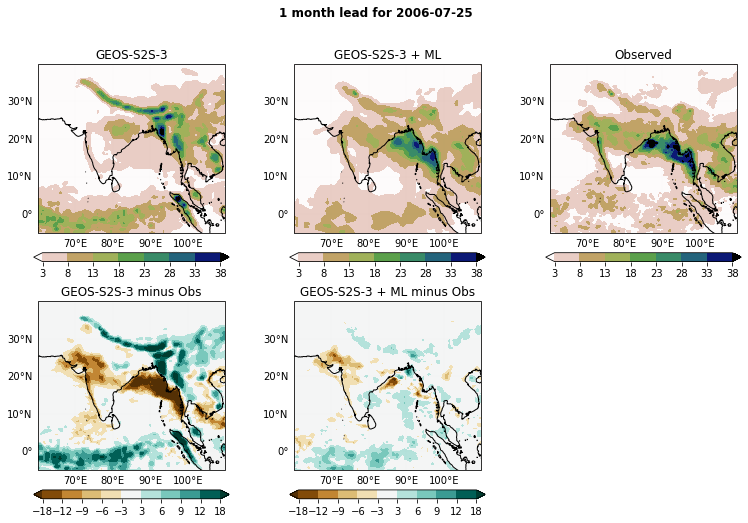

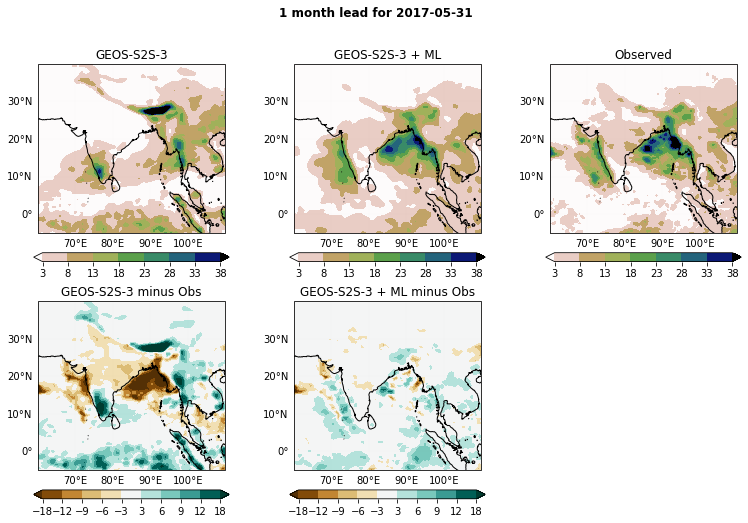

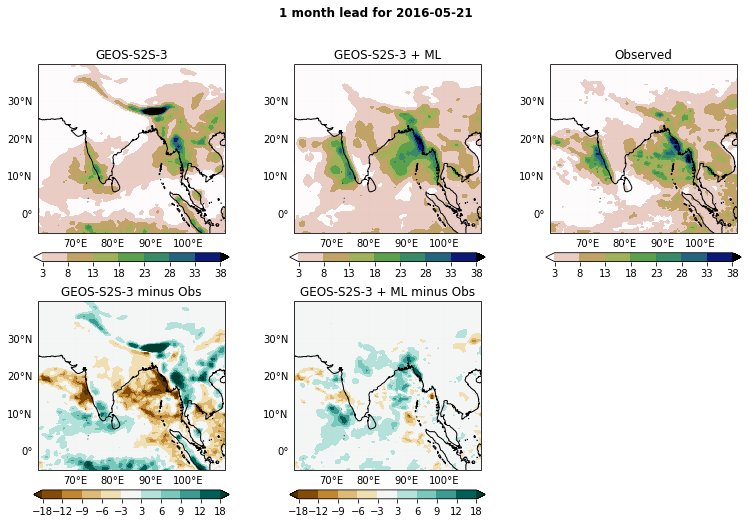

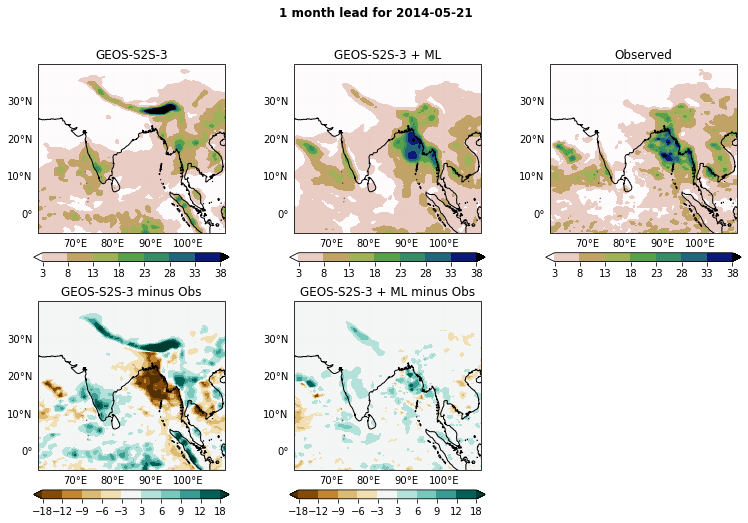

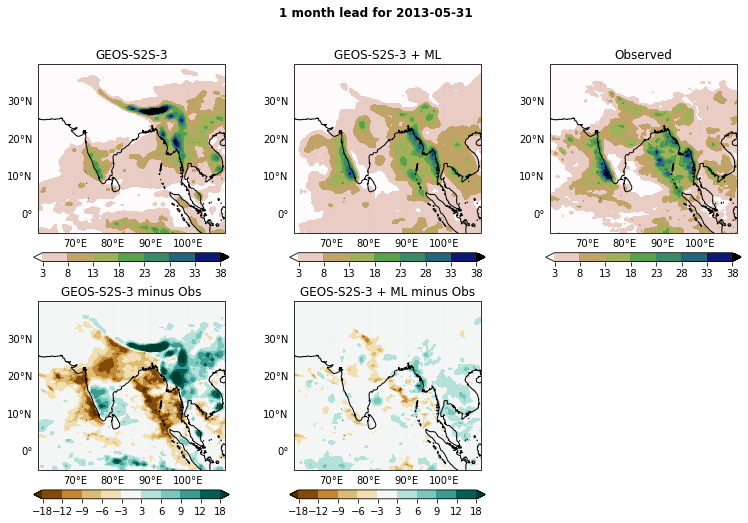

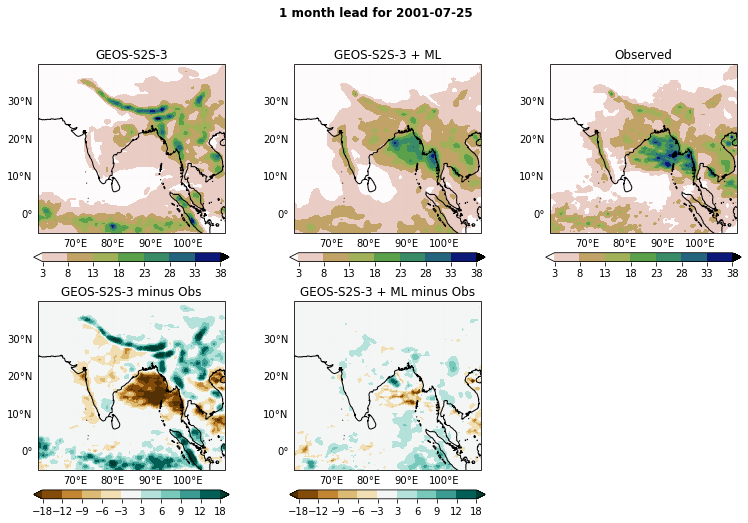

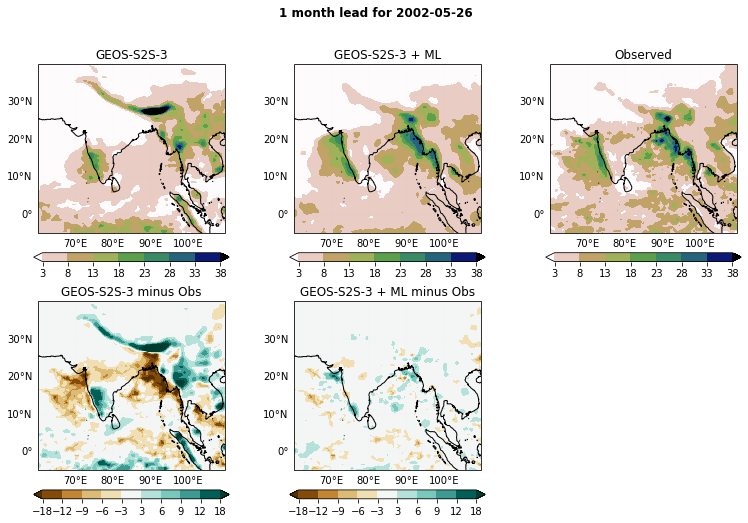

In [177]:
for i in range(39):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):

        nn=i
        l=0
        fig=plt.figure(figsize=(13,8))
        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' month lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
    else:
        None

0
1
2
7
9
14
18
22
23
28
29
32
34
35


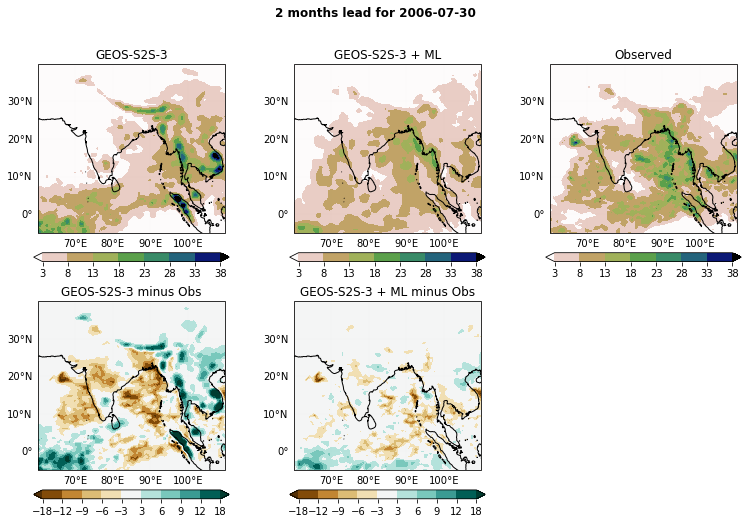

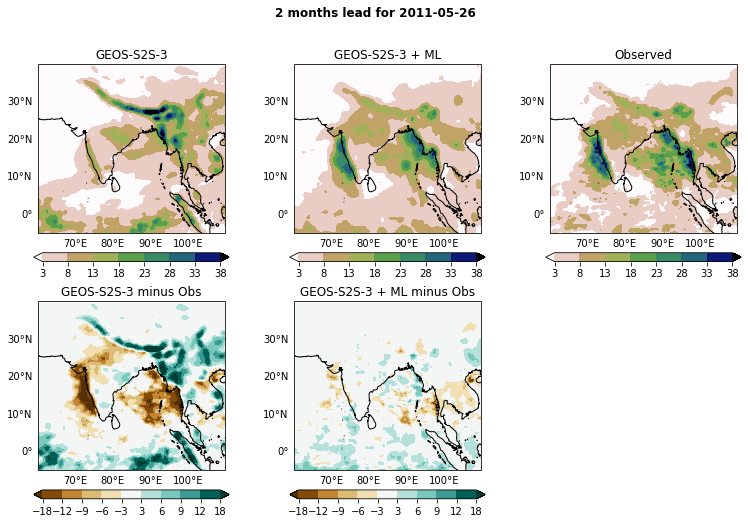

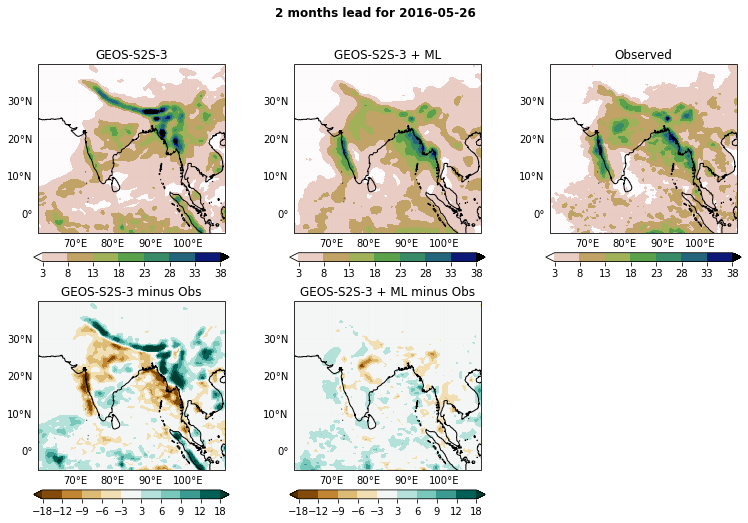

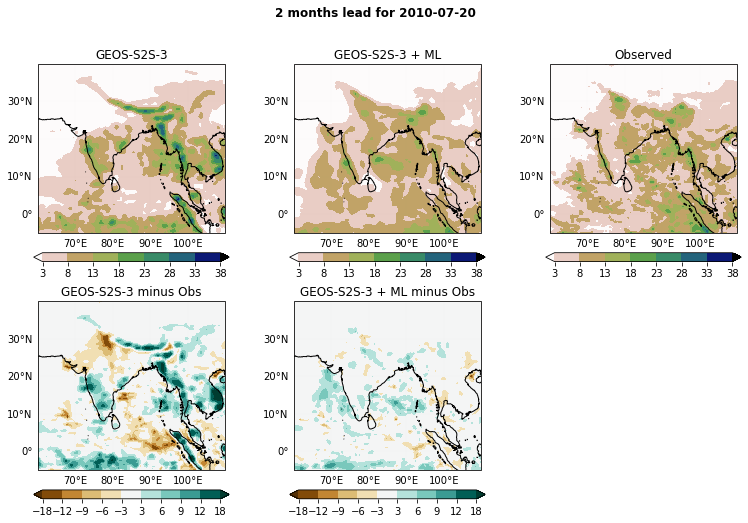

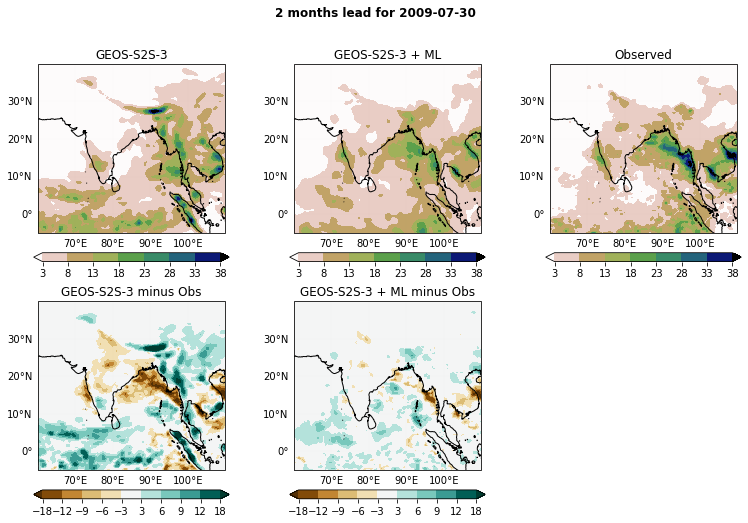

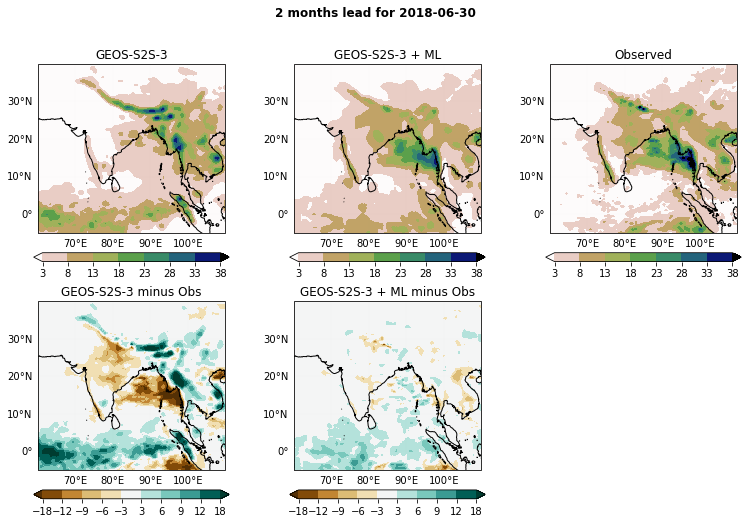

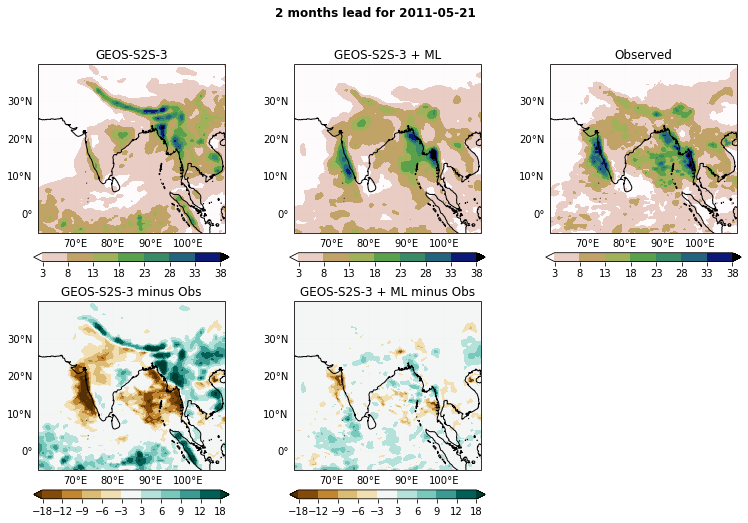

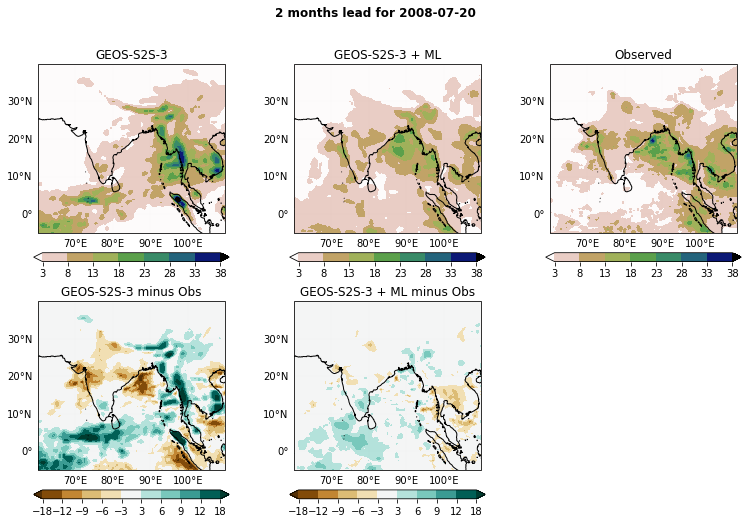

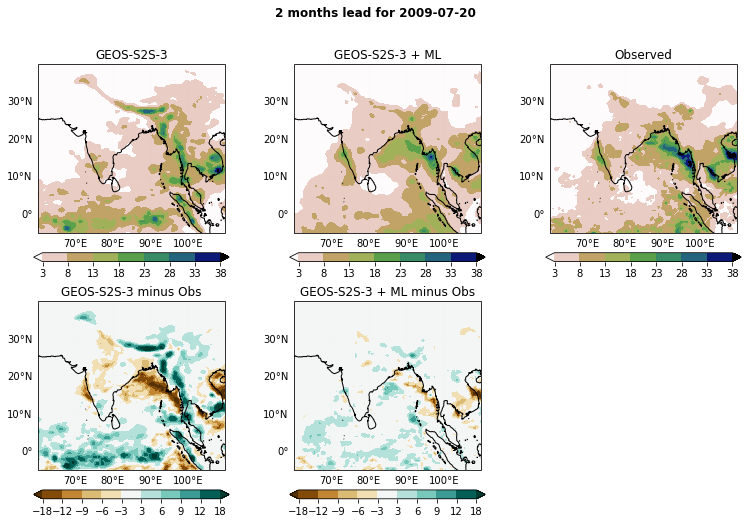

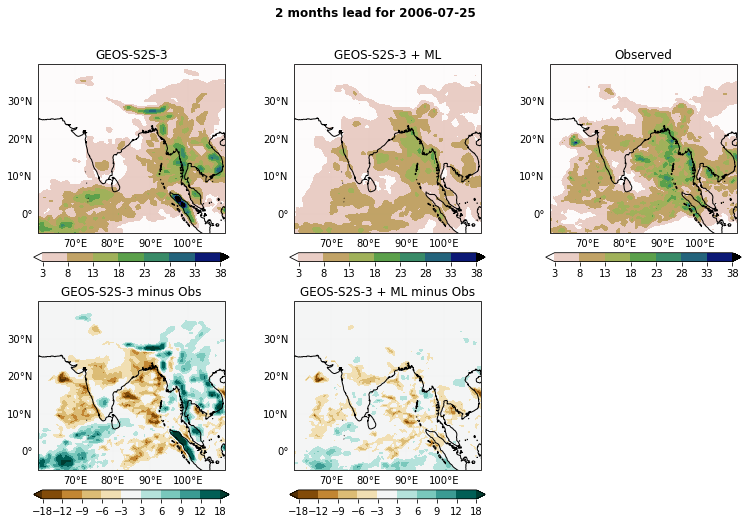

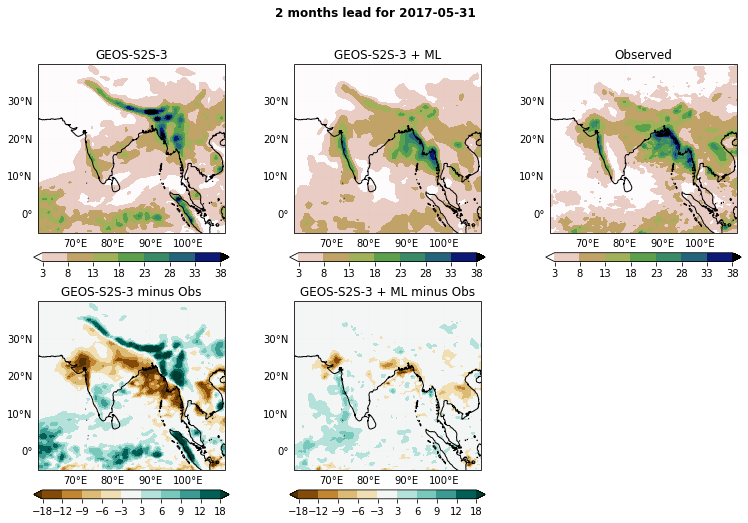

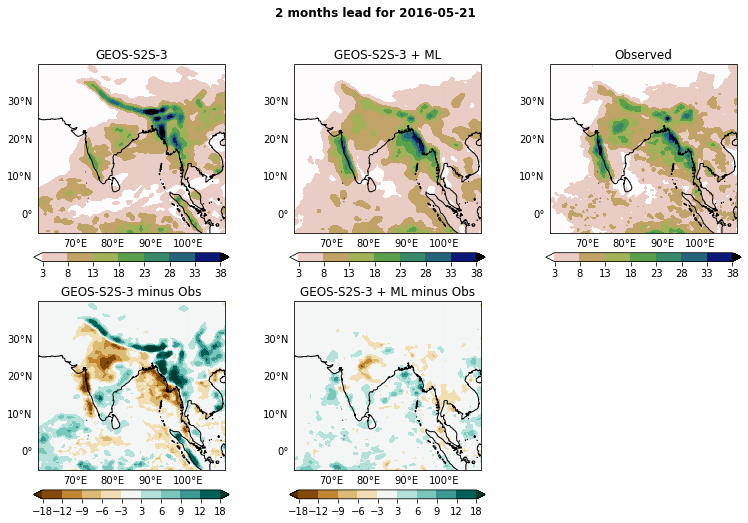

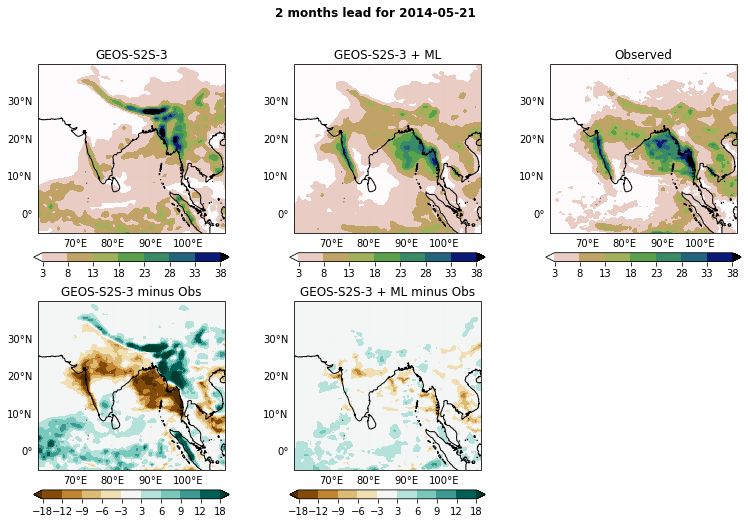

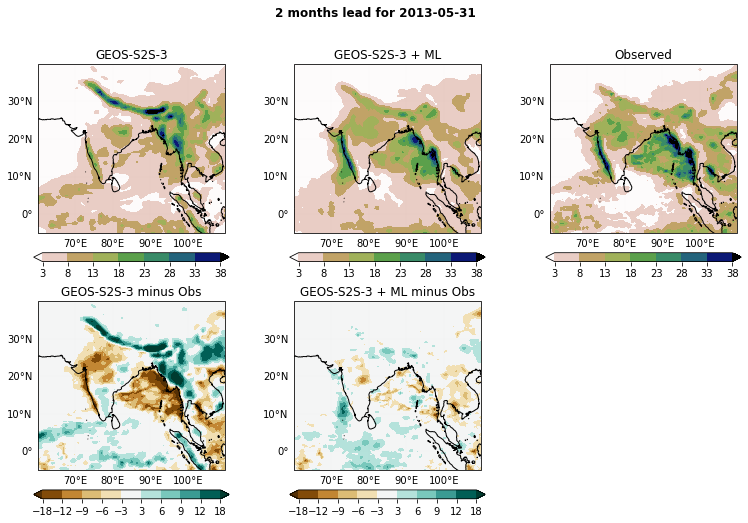

In [178]:


for i in range(36):
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(13,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('GEOS-S2S-3 + ML')

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('GEOS-S2S-3')

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('Observed')

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('GEOS-S2S-3 + ML minus Obs')

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('GEOS-S2S-3 minus Obs')
        plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')

2


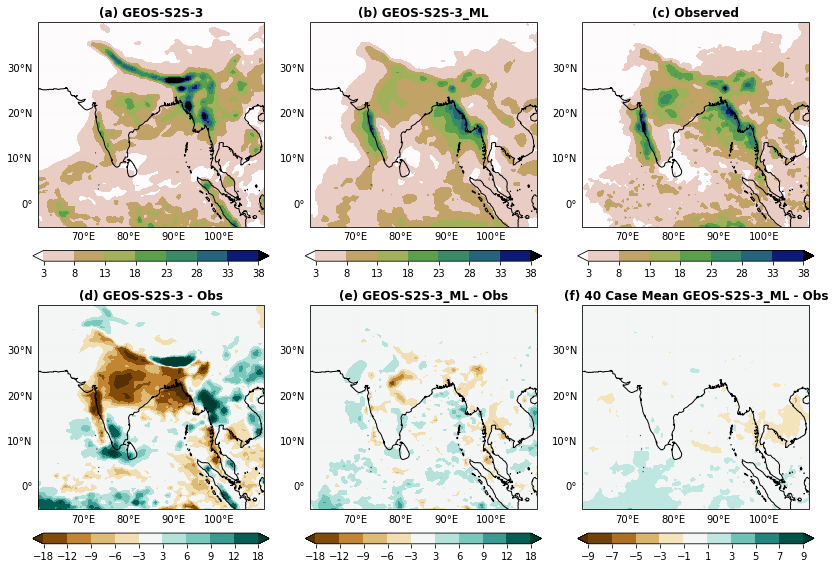

In [179]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

2


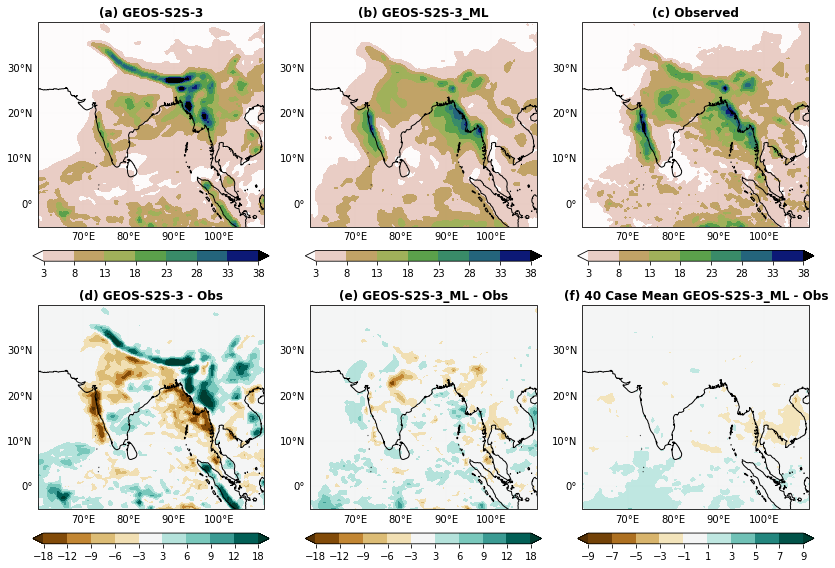

In [180]:
    i=2
    if (int(str((date[500+i]))[5:7])>4)&(int(str((date[500+i]))[5:7])<8):
        print(i)
    
        nn=i
        l=1

        clf=np.arange(3,41,5)
        cmap='gist_earth_r'
        fig=plt.figure(figsize=(11.5,8))

        plot(original_Yp[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,2],fig=fig)
        plt.title('(b) GEOS-S2S-3_ML',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1],lon,lat,cmap=cmap,clf=clf,sub=[2,3,1],fig=fig)
        plt.title('(a) GEOS-S2S-3',fontweight='bold', fontsize=12)

        plot(original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,3],fig=fig)
        plt.title('(c) Observed',fontweight='bold', fontsize=12)

        clf=np.array([-18,-12,-9,-6,-3,3,6,9,12,18])
        cmap='BrBG'


        plot(original_Yp[nn,:,:,l]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,5],fig=fig)
        plt.title('(e) GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)

        plot(original_X[nn,:,:,l+1]-original_Y[nn,:,:,l],lon,lat,cmap=cmap,clf=clf,sub=[2,3,4],fig=fig)
        plt.title('(d) GEOS-S2S-3 - Obs',fontweight='bold', fontsize=12)

        plot(np.nanmean(original_Yp[:,:,:,l]-original_Y[:,:,:,l],0),lon,lat,cmap=cmap,clf=np.arange(-9,9.1,2),sub=[2,3,6],fig=fig)
        plt.title('(f) 40 Case Mean GEOS-S2S-3_ML - Obs',fontweight='bold', fontsize=12)
        
        plt.tight_layout()
        #plt.suptitle(str(l+1)+' months lead for '+str(date[500+nn])[:10],fontsize=12,fontweight='bold')
        #plt.savefig(str(RESULTS_DIR / "GEOSML.png"),dpi=200)

In [181]:
X_sample=original_X.astype(np.float32)
X_sample = tf.convert_to_tensor(X_sample, dtype=tf.float32)
# Using GradientTape to calculate the saliency map
with tf.GradientTape() as tape:
    # Watch the input tensor
    tape.watch(X_sample)

    # Predict with the model
    predictions = model(X_sample)

    # Assume we are interested in the mean of the predictions (customize your loss appropriately)
    loss = tf.reduce_mean(predictions)

# Compute gradients of the loss w.r.t the input image
grads = tape.gradient(loss, X_sample)

# Normalize the gradients
normalized_grads = grads / (tf.sqrt(tf.reduce_mean(tf.square(grads))) + 1e-5)

In [182]:
saliency_map = normalized_grads.numpy()

In [183]:
saliency_map.shape

(40, 91, 101, 7)

<GeoAxesSubplot:>

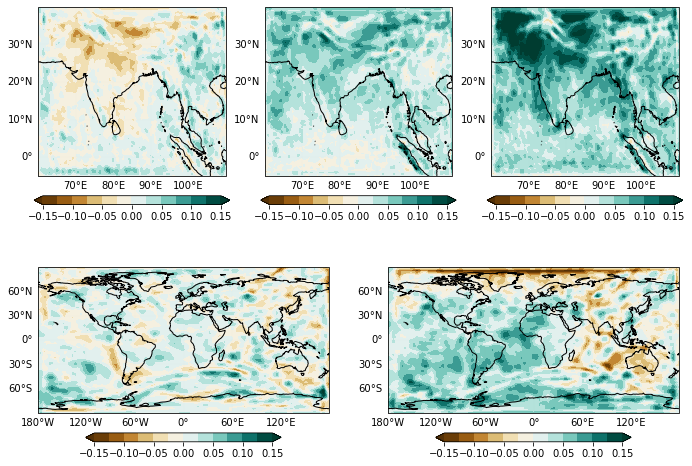

In [184]:
fig=plt.figure(figsize=(11.5,8))
clf=np.arange(-1.5,1.51,.25)*1e-1

plot(np.nanmean(saliency_map[:,:,:,0],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,1],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,1],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,2],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,2],0),lon,lat,clf=clf,cmap=cmap,sub=[2,3,3],fig=fig)

#clf=np.arange(-1.5,1.51,.25)*1e-1
plot(np.nanmean(saliency_map[:,:,:,5],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,3],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,6],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,4],fig=fig)

<GeoAxesSubplot:>

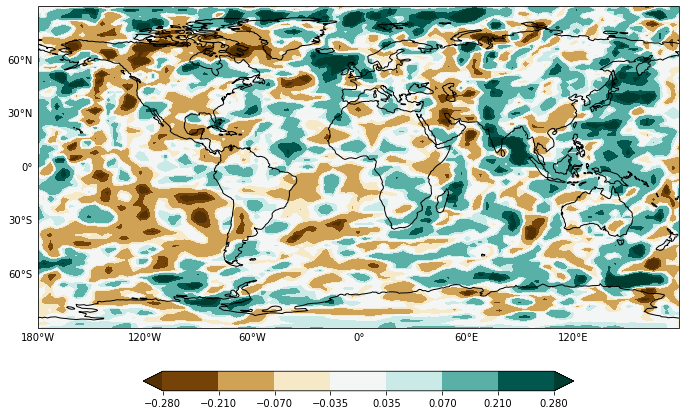

In [185]:
fig=plt.figure(figsize=(11.5,8))
clf=np.array([-.8,-.6,-.2,-.1,.1,.2,.6,.8])*3.5e-1
plot(np.nanmean(saliency_map[2:3,:,:,4],0),lon1,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig,)

In [186]:
def wrap360(ds, lon='lon'):
    """
    wrap longitude coordinates to 0..360

    Parameters    ----------
    ds : Dataset
        object with longitude coordinates
    lon : string
        name of the longitude ('lon', 'longitude', ...)

    Returns
    -------
    wrapped : Dataset
        Another dataset array wrapped around.
    """

    # wrap -180..179 to 0..359
    ds.coords['lon'] = np.mod(ds['lon'], 360)

    # sort the data
    return ds.reindex({ 'lon' : np.sort(ds['lon'])})

<GeoAxesSubplot:>

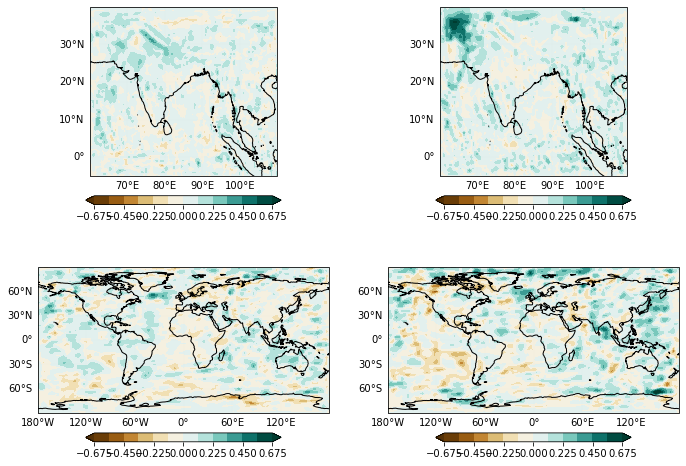

In [187]:
fig=plt.figure(figsize=(11.5,8))
clf=np.arange(-1.5,1.51,.25)*4.5e-1

plot((saliency_map[2,:,:,1]),lon,lat,clf=clf,cmap=cmap,sub=[2,2,1],fig=fig)
plot((saliency_map[2,:,:,2]),lon,lat,clf=clf,cmap=cmap,sub=[2,2,2],fig=fig)

#clf=np.arange(-1.5,1.51,.25)*2e-1
plot(saliency_map[2,:,:,3],lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,3],fig=fig)
plot(saliency_map[2,:,:,4],lon1,lat1,clf=clf,cmap=cmap,sub=[2,2,4],fig=fig)

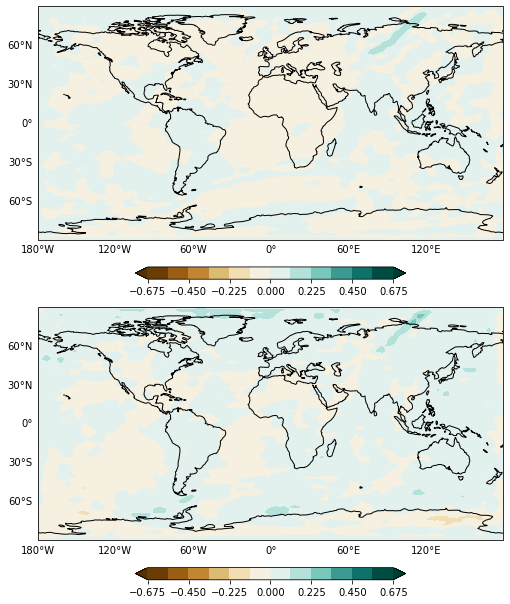

In [188]:
#clf=np.arange(-1.5,1.51,.25)*1e-1
fig=plt.figure(figsize=(11.5,8.5))
plot(np.nanmean(saliency_map[:,:,:,3],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,1,1],fig=fig)
plot(np.nanmean(saliency_map[:,:,:,4],0),lon1,lat1,clf=clf,cmap=cmap,sub=[2,1,2],fig=fig)
plt.tight_layout()

In [189]:
sal=np.nanmean(saliency_map[:,:,:,6],0)

In [190]:
sal.shape

(91, 101)

In [191]:
ds = xr.Dataset({
    'sal': xr.DataArray(
                data   = sal,   # enter data here
                dims   = ['lat','lon'],
                coords = {'lon': lon1, 'lat': lat1},
                attrs  = {
                    '_FillValue': -999.9,
                    'units'     : 'W/m2'
                    }
                ),
            },
        attrs = {'example_attr': 'this is a global attribute'}
    )

In [192]:
ds

<xarray.Dataset>
Dimensions:  (lat: 91, lon: 101)
Coordinates:
  * lon      (lon) float64 -180.0 -176.4 -172.8 -169.2 ... 172.3 175.9 179.5
  * lat      (lat) float64 90.0 88.0 86.0 84.0 82.0 ... -84.0 -86.0 -88.0 -90.0
Data variables:
    sal      (lat, lon) float32 0.009719375 0.02008281 ... 0.015069905
Attributes:
    example_attr:  this is a global attribute

In [193]:
sal1=wrap360(ds,lon=ds.lon)

In [194]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

#fig = plt.figure(figsize=(11, 8.5))

# Create an axes with the PlateCarree projection

def plot(data,lon,lat,cmap='coolwarm',fig=[],nx=[],ny=[],sub=[1,1,1],clf=[],frac=.045):

    ax = fig.add_subplot(sub[0], sub[1], sub[2], projection=ccrs.PlateCarree(central_longitude=180))

    # Example usage of the axes
    ax.coastlines()  # Adds coastlines
    # try:
    #     ax.set_extent([nx[0], nx[1], ny[0], ny[1]]) # define the boundary
    # except:
    #     None
    ax.set_extent([60,250, -40, 40])
    try:
        cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both',levels=clf)
    except:
                cc=ax.contourf(lon,lat,data,cmap=cmap,extend='both')

    plt.colorbar(cc,orientation='horizontal',  shrink=5,pad=0.1,fraction=frac)
    gl = ax.gridlines(draw_labels=True, linewidth=0.01)

    gl.xlabels_top = False  # Disable labels on the top
    gl.ylabels_right = False  # Disable labels on the right
    gl.xformatter = ccrs.cartopy.mpl.gridliner.LONGITUDE_FORMATTER
    gl.yformatter = ccrs.cartopy.mpl.gridliner.LATITUDE_FORMATTER

    return(ax)
#map5.contourf(lon,lat,Yp_norm_test[nn,:,:,1])


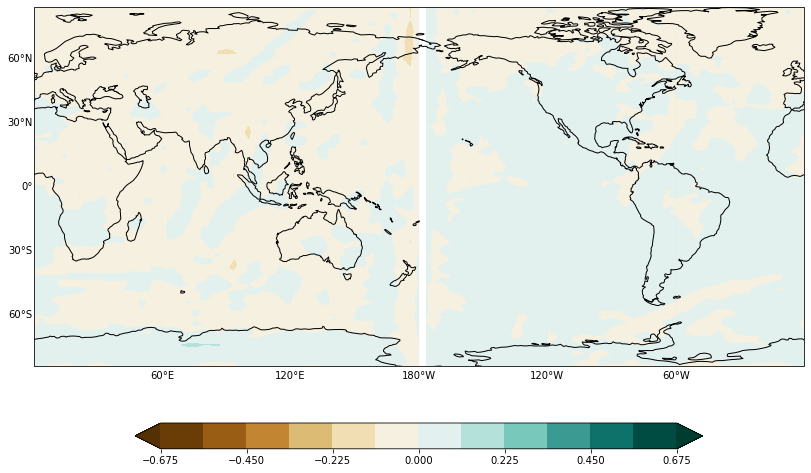

In [164]:
fig=plt.figure(figsize=(11,8.5))

ax=plot(sal,sal1.lon,lat1,clf=clf,cmap=cmap,sub=[1,1,1],fig=fig)

plt.tight_layout()

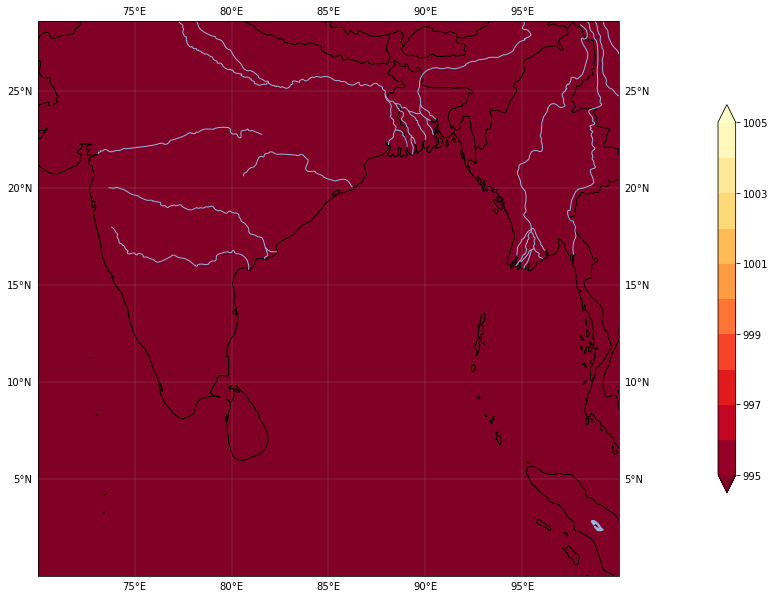

In [165]:
# Create the subplots
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(14, 8),
                        subplot_kw={'projection': ccrs.PlateCarree()})

# Plot Pearson and Spearman Correlation between Precipitation and temperature on the subplots
# for i, ax in enumerate(axs.flat):
cs = ax.contourf(lon1, lat1,sal , 30, cmap='YlOrRd_r', extend='both', transform=ccrs.PlateCarree(), levels=np.arange(995,1006,1))
ax.add_feature(cf.COASTLINE)
ax.add_feature(cf.BORDERS, linewidth=1)
ax.add_feature(cf.OCEAN)
ax.add_feature(cf.LAKES)
ax.add_feature(cf.LAND)
ax.add_feature(cf.RIVERS)
ax.set_extent([70, 100, 0, 28])
bx = ax.gridlines(draw_labels=True, linewidth=0.2)
#ax.set_title(corr_title[i], fontsize=12, pad=10, y=1.04, loc="left")

# Add vertical colorbar to each subplot with a custom size
cbar = plt.colorbar(cs, ax=ax, orientation='vertical', pad=0.1, shrink=0.7)
cbar.ax.tick_params(labelsize=10)

# Adjust the spacing between subplots and display the plot
plt.tight_layout()

plt.show()